# A single-angle transport solve on a slab

The smallest thing `jax-sn` can do: solve the transport equation for **one** direction
$\Omega$, in **one** energy group, with **no** scattering. That reduces the full $S_N$
operator to a single transport sweep,

$$\mathcal{T}\,\psi \;=\; \left(\Omega \cdot \nabla + \sigma\right)\psi \;=\; q ,$$

which after finite-element discretisation becomes $\mathbf{T}\,\psi = \overline{\mathbf{H}}\,q$
— the mass operator maps the source onto the basis, and inverting the transport operator is
a sweep along $\Omega$ through the mesh.

This example builds that problem in 1D and in 3D and checks both against the analytical
solution for a uniform box with a uniform isotropic source, which `jax-sn` ships as
`jax_sn.analytical_solutions.psi_isotropic_box`.

It is also a tour of the **data + strategy** pattern the whole package is built on: an
operator is a data pytree (`TransportData`, `MassData`) plus a stateless strategy object
saying *how* to apply it (`BatchedSweep`, `VmapMass`). Swapping in a GPU kernel later means
swapping the strategy, not the operator.

In [1]:
import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"   # this problem is small; the CPU backend is plenty

import jax
import jax.numpy as jnp
import numpy as onp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)

from jax_sn.domain import CrossSectionData, Domain
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex, SolutionDomain

from jax_sn.operators.mass_operator import MassOperator, MassData, VmapMass
from jax_sn.operators.transport_operator import (
    BasicSweepData, TransportData, TransportOperatorSingleAngle,
    BatchedForward, BatchedSweep,
)
from jax_sn.analytical_solutions import psi_isotropic_box

## Building the problem

`setup_slab` walks the standard construction chain once, for any dimension:

1. `create_cartesian_setup` meshes the unit box into simplices and tags each element with a
   cross-section region and a source strength.
2. `Domain` adds the topology (face connectivity) that a sweep needs.
3. `SolutionDomain` ties that geometry to a FEM basis — here Lagrangian simplices of a given
   degree — and precomputes the FEM matrices and geometric factors.
4. `BasicSweepData.from_domain_angle` topologically sorts the elements along $\Omega$. This is
   the *non-differentiable* half of the operator data: pure combinatorics, computed once.
5. The two operators are then assembled as `data + strategy`.

`BatchedForward(batch_size)` / `BatchedSweep(batch_size)` walk the sweep ordering in chunks of
`batch_size` elements — the alternative `VmapForward` / `VmapSweep` pair vectorises over the
whole ordering at once, trading memory for speed.

In [2]:
def setup_slab(dim, sigma, q, degree, n_cells, angle, batch_size):
    '''Uniform unit box, uniform source, one energy group, one direction.'''
    xs = CrossSectionData.constant(sigma, 1, 1)
    verts, conn, cross_sections, sources = create_cartesian_setup(
        dim, [[(1.0, n_cells)]] * dim,
        cross_sections_regions=[xs], source_regions=[q], inhomogeneity_direction=0,
    )
    element = BasixLagrangianSimplex(degree, dim)
    domain  = Domain.from_mesh_and_cross_sections((verts, conn), element.face_template, cross_sections)
    sd      = SolutionDomain.from_element_and_domain(element, domain)

    # element-wise source strengths -> one value per (element, basis function)
    source = jnp.repeat(sources, element.n_basis, axis=-1).reshape(-1, element.n_basis)

    sweep_data     = BasicSweepData.from_domain_angle(domain, angle)
    transport_data = TransportData(sd.spatial_data, 0, angle, sweep_data)

    mass_op      = MassOperator(MassData(sd.fem_matrices, sd.precomputed_geometric_data),
                                (), VmapMass())
    transport_op = TransportOperatorSingleAngle(transport_data,
                                                BatchedForward(batch_size), BatchedSweep(batch_size))
    return sd, source, mass_op, transport_op

In [3]:
angle = jnp.array([1.0, 0.5, 0.0])
angle = angle / jnp.linalg.norm(angle)     # a direction that is not aligned with the mesh
sigma, q = 5.0, 3.0

print(f"direction    : {angle}")
print(f"cross section: {sigma}   source: {q}")

direction    : [0.89442719 0.4472136  0.        ]
cross section: 5.0   source: 3.0


## 1D

In one dimension the equation is $\mu \frac{d\psi}{dx} + \sigma \psi = q$, with
$\mu = \Omega_x$. The exact solution for a slab of width $a$ with a vacuum boundary at
$x = 0$ is

$$\psi(x) = \frac{q}{\sigma}\left(1 - e^{-\sigma x / \mu}\right),$$

i.e. the flux saturates at $q/\sigma$ once the slab is optically thick.

In [4]:
sd, source, mass_op, transport_op = setup_slab(
    dim=1, sigma=sigma, q=q, degree=2, n_cells=20, angle=angle[:1], batch_size=10,
)

# psi = T^-1 (H q)  -- one sweep, no iteration, because there is no scattering
solution = transport_op.inv(mass_op.mv(source))
solution.shape   # (n_elements, n_basis)

(20, 3)

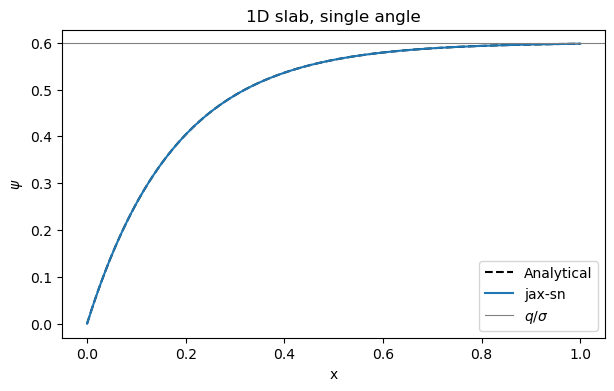

max abs error: 1.85e-04


In [5]:
x_vals = onp.linspace(0.0, 1.0, 1000)[:, None]

numerical  = sd.interpolate(jnp.asarray(x_vals), solution)
analytical = psi_isotropic_box(x_vals, 1.0, onp.asarray(angle[:1]), sigma, q)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_vals, analytical, color="black", linestyle="dashed", label="Analytical")
ax.plot(x_vals, numerical, label="jax-sn")
ax.axhline(q / sigma, color="grey", linewidth=0.8, label=r"$q/\sigma$")
ax.set_xlabel("x"); ax.set_ylabel(r"$\psi$")
ax.set_title("1D slab, single angle"); ax.legend()
plt.show()

print(f"max abs error: {onp.max(onp.abs(onp.asarray(numerical) - analytical)):.2e}")

## Convergence

Because the exact solution is known, the discretisation error can be measured directly. For a
Lagrangian basis of degree $p$ the $L_2$ error should fall as $h^{p+1}$, i.e. with slope
$-(p+1)$ against the number of cells on a log-log plot.

The $L_2$ norm is evaluated element-wise on a quadrature rule of high enough order that the
quadrature error stays well below the discretisation error — mapping the reference-element
quadrature points into real space, evaluating both solutions there, and weighting by the
volume Jacobian.

`psi_isotropic_box` is a NumPy helper, so it cannot be traced by the `vmap` below; the 1D
closed form is spelled out in `jnp` instead.

In [6]:
def compute_L2_error(solution, analytical_f, sd, quad_order):
    '''L2 norm of (numerical - analytical) over the whole domain.'''
    quad_points, quad_weights = sd.element.volume_quadrature_order(quad_order)

    def _squared_error(elem_idx):
        elem_tot    = jnp.full(quad_points.shape[0], elem_idx, dtype=int)
        real_coords = sd.element.real_coordinates(quad_points, elem_tot, sd.domain,
                                                  sd.precomputed_geometric_data)
        analytical  = analytical_f(real_coords).flatten()
        numerical   = sd.element.interpolate_from_local_coordinate(quad_points, elem_tot, solution)
        return jnp.sum(quad_weights * (numerical - analytical)**2
                       * sd.precomputed_geometric_data.vol_jacobians_det[elem_idx])

    return jnp.sqrt(jnp.sum(jax.vmap(_squared_error)(jnp.arange(sd.domain.n_elements))))


def psi_1d(points, mu, sigma, q):
    '''The 1D closed form, traceable by jax.'''
    return (q / sigma) * (1.0 - jnp.exp(-sigma * points[..., 0] / mu))

In [7]:
n_cells_list = onp.unique(onp.logspace(onp.log10(5), onp.log10(80), num=10).astype(int))
analytical_f = lambda pts: psi_1d(pts, angle[0], sigma, q)

errors = {}
for degree in [1, 2, 3]:
    errs = []
    for n_cells in n_cells_list:
        sd_c, source_c, mass_c, transport_c = setup_slab(
            dim=1, sigma=sigma, q=q, degree=degree, n_cells=int(n_cells),
            angle=angle[:1], batch_size=10,
        )
        sol = transport_c.inv(mass_c.mv(source_c))
        errs.append(float(compute_L2_error(sol, analytical_f, sd_c, quad_order=8 * (degree + 1))))
    errors[degree] = errs

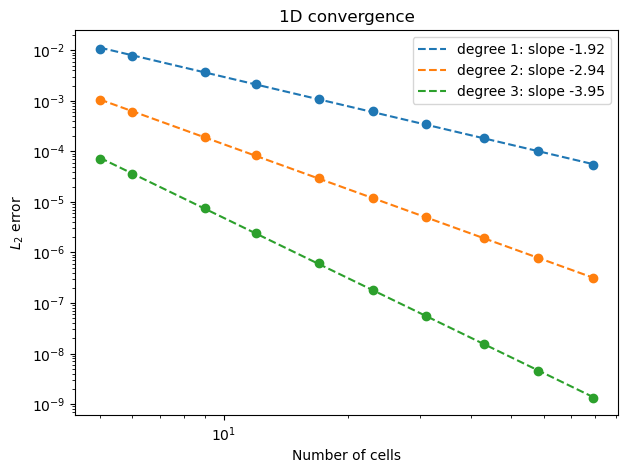

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
for degree, errs in errors.items():
    slope, intercept = onp.polyfit(onp.log10(n_cells_list), onp.log10(errs), 1)
    line, = ax.loglog(n_cells_list, errs, marker="o", linestyle="none")
    ax.loglog(n_cells_list, 10**intercept * n_cells_list**slope, linestyle="dashed",
              color=line.get_color(), label=f"degree {degree}: slope {slope:.2f}")
ax.set_xlabel("Number of cells"); ax.set_ylabel(r"$L_2$ error")
ax.set_title("1D convergence"); ax.legend()
plt.show()

The measured slopes come out at $-(p+1)$ for each degree, as they should.

## 3D

Nothing about the construction changes in 3D — the same `setup_slab` call with `dim=3`.
What changes is the sweep: the topological ordering is now over a tetrahedral mesh, and the
answer is no longer a pure slab solution. A ray reaching $(x, y, z)$ leaves the box through
whichever face it hits first going backwards along $\Omega$, so the analytical solution uses
the distance to that face,

$$\psi(\mathbf{r}) = \frac{q}{\sigma}\left(1 - e^{-\sigma s}\right),
\qquad s = \min\left(\tfrac{x}{\mu}, \tfrac{y}{\eta}, \tfrac{z}{\xi}\right).$$

Along the line $y = z = 0.2$ the flux therefore stops following the 1D curve once the
$y$-boundary becomes the closest one.

In [9]:
sd3, source3, mass_op3, transport_op3 = setup_slab(
    dim=3, sigma=sigma, q=q, degree=2, n_cells=10, angle=angle, batch_size=100,
)
print(f"{sd3.domain.n_elements} tetrahedra, {sd3.n_basis} basis functions each")

result = transport_op3.inv(mass_op3.mv(source3))

6000 tetrahedra, 10 basis functions each


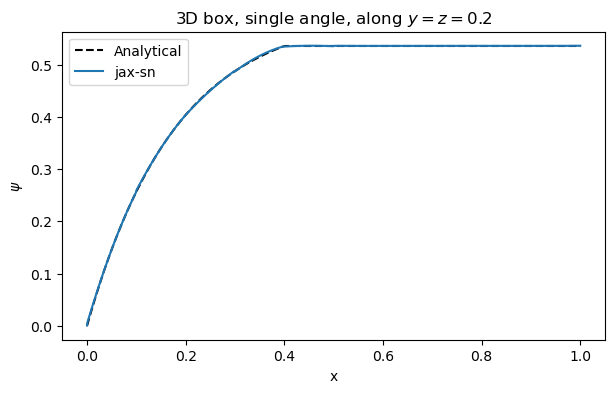

max abs error: 3.98e-03


In [10]:
points = onp.hstack([x_vals, onp.full_like(x_vals, 0.2), onp.full_like(x_vals, 0.2)])

numerical_3d  = sd3.interpolate(jnp.asarray(points), result)
analytical_3d = psi_isotropic_box(points, 1.0, onp.asarray(angle), sigma, q)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x_vals, analytical_3d, color="black", linestyle="dashed", label="Analytical")
ax.plot(x_vals, numerical_3d, label="jax-sn")
ax.set_xlabel("x"); ax.set_ylabel(r"$\psi$")
ax.set_title("3D box, single angle, along $y = z = 0.2$"); ax.legend()
plt.show()

print(f"max abs error: {onp.max(onp.abs(onp.asarray(numerical_3d) - analytical_3d)):.2e}")

## A note on the sweep

The transport inverse is sequential by nature: an element can only be solved once every
element upwind of it has been. `BasicSweepData` records that dependency as *levels* — all
elements in one level are mutually independent and can be solved in parallel, and the levels
themselves must run in order. The width of the narrowest level is what caps the available
parallelism, and it is the number that decides whether a GPU kernel is worth it here.

In [11]:
level_widths = jnp.bincount(transport_op3.data.sweep_data.levels)
print(f"levels                    : {level_widths.shape[0]}")
print(f"narrowest / widest level  : {int(jnp.min(level_widths))} / {int(jnp.max(level_widths))}")
print(f"mean elements per level   : {float(jnp.mean(level_widths)):.1f}")

levels                    : 41
narrowest / widest level  : 100 / 200
mean elements per level   : 146.3


## Where to go from here

- **More angles.** A real $S_N$ calculation sweeps a whole quadrature set;
  `TransportOperatorMultiAngle` lifts a single-angle kernel over the angle axis
  (`VmapAngles` / `ScanAngles`).
- **Scattering.** With scattering the problem is no longer a single sweep — the single-group
  operator $I - M T^{-1} H D S$ has to be inverted iteratively.
- **Faster kernels.** `BatchedSweep` is the plain-JAX reference. `VmapPallasSweep` and the
  Warp level sweep are drop-in replacements for the same operator; see `perf_tests/` for how
  they compare.